In [68]:
import numpy as np
import os
import pandas as pd
from scipy.stats import pointbiserialr, chi2_contingency

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Функция чтения
def load_movielens(data_dir: str) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    '''
    Function to load MovieLense Dataset
    Input:
     - data_dir: str - directory with files movies.dat, ratings.dat, users.dat
     
    Output:
     - tuple with movies, ratings, users: pd.Dataframe - tuple with loaded dataset in pandas Dataframes
    '''

    def parse_data_file(filepath: str, column_names: list[str]) -> pd.DataFrame:
        '''
        modified read_csv
        '''
        return pd.read_csv(
            filepath,
            sep='::',
            names=column_names,
            engine='python',
            encoding='latin-1'
        )
    
    ratings = parse_data_file(
        os.path.join(data_dir, "ratings.dat"),
        column_names=["UserID","MovieID","Rating","Timestamp"]
    )

    users = parse_data_file(
        os.path.join(data_dir, "users.dat"),
        column_names=["UserID","Gender","Age","Occupation","Zip-code"]
    )

    movies = parse_data_file(
        os.path.join(data_dir, "movies.dat"),
        column_names=["MovieID","Title","Genres"]
    )

    return movies, ratings, users

In [3]:
DATA_DIR = ".\\MovieLensData"

movies, ratings, users = load_movielens(DATA_DIR)

# Анализ состава данных

In [18]:
# Информация по Ratings
print("=== Ratings ===")
print(f"Размер: {ratings.shape}")
display(ratings.head())
print(ratings.info())

=== Ratings ===
Размер: (1000209, 4)


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   UserID     1000209 non-null  int64
 1   MovieID    1000209 non-null  int64
 2   Rating     1000209 non-null  int64
 3   Timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB
None


In [13]:
# Информация по Users
print("\n=== Users ===")
print(f"Размер: {users.shape}")
display(users.head())


=== Users ===
Размер: (6040, 5)


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [14]:
# Информация по Movies
print("\n=== Movies ===")
print(f"Размер: {movies.shape}")
display(movies.head())


=== Movies ===
Размер: (3883, 3)


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [15]:
# Статистика оценок и пропуски
print("\n=== Статистика оценок ===")
print(ratings['Rating'].describe())
print(ratings['Rating'].value_counts().sort_index())

print("\n=== Пропущенные значения ===")
print(f"Ratings: {ratings.isnull().sum().sum()}")
print(f"Users: {users.isnull().sum().sum()}")
print(f"Movies: {movies.isnull().sum().sum()}")


=== Статистика оценок ===
count    1.000209e+06
mean     3.581564e+00
std      1.117102e+00
min      1.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: Rating, dtype: float64
Rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

=== Пропущенные значения ===
Ratings: 0
Users: 0
Movies: 0


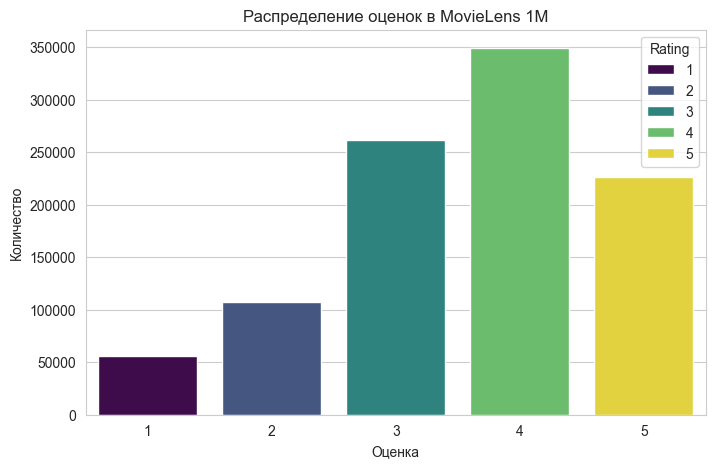

In [16]:
# Распределение оценок
# Настройка стиля
sns.set_style("whitegrid")


plt.figure(figsize=(8, 5))
sns.countplot(data=ratings, x='Rating', hue='Rating', palette='viridis')
plt.title('Распределение оценок в MovieLens 1M')
plt.xlabel('Оценка')
plt.ylabel('Количество')
plt.show()

In [17]:
# Топ-10 самых оцениваемых фильмов
top_movies = ratings['MovieID'].value_counts().head(10)
top_movies_titles = movies[movies['MovieID'].isin(top_movies.index)][['MovieID', 'Title']]
print("\nТоп-10 самых оцениваемых фильмов:")
top_movies_titles.merge(
    top_movies.reset_index().rename(columns={'MovieID': 'MovieID', 'count': 'RatingCount'}),
    on='MovieID'
).sort_values('RatingCount',ascending=False)


Топ-10 самых оцениваемых фильмов:


,MovieID,Title,RatingCount
9,2858,American Beauty (1999),3428
0,260,Star Wars: Episode IV - A New Hope (1977),2991
4,1196,Star Wars: Episode V - The Empire Strikes Back...,2990
5,1210,Star Wars: Episode VI - Return of the Jedi (1983),2883
1,480,Jurassic Park (1993),2672
7,2028,Saving Private Ryan (1998),2653
2,589,Terminator 2: Judgment Day (1991),2649
8,2571,"Matrix, The (1999)",2590
6,1270,Back to the Future (1985),2583
3,593,"Silence of the Lambs, The (1991)",2578


269.88909875876953


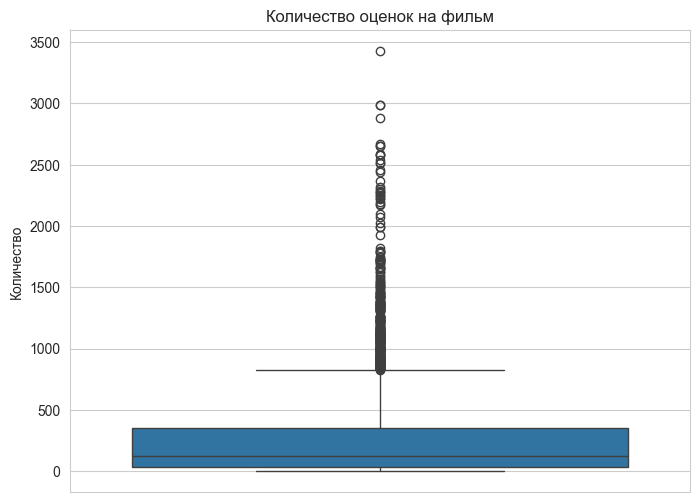

In [18]:
# Boxplot количества оценок на фильм
stats = ratings.groupby('MovieID')['Rating'].agg(['count']).reset_index()
print(stats['count'].mean())
plt.figure(figsize=(8, 6))
sns.boxplot(stats, y=stats['count'])
plt.title('Количество оценок на фильм')
plt.ylabel('Количество')
plt.show()

In [19]:
# Топ 10 самых высоко оцененных фильмов
stats = ratings.groupby('MovieID')['Rating'].agg(['mean', 'count']).reset_index()
stats.columns = ['MovieID', 'AvgRating', 'RatingCount']
top_movies = pd.merge(movies, stats, on='MovieID', how='left', validate='one_to_one')
result = (
    top_movies[top_movies['RatingCount'] > 100]
    .sort_values('AvgRating', ascending=False)
)
print("Топ 10 самых высоко оцененных фильмов (мин. 100 оценок):")
result[['MovieID', 'Title', 'AvgRating','RatingCount']].head(10)


Топ 10 самых высоко оцененных фильмов (мин. 100 оценок):


,MovieID,Title,AvgRating,RatingCount
1950,2019,Seven Samurai (The Magnificent Seven) (Shichin...,4.560510,628.0
315,318,"Shawshank Redemption, The (1994)",4.554558,2227.0
847,858,"Godfather, The (1972)",4.524966,2223.0
735,745,"Close Shave, A (1995)",4.520548,657.0
49,50,"Usual Suspects, The (1995)",4.517106,1783.0
523,527,Schindler's List (1993),4.510417,2304.0
1132,1148,"Wrong Trousers, The (1993)",4.507937,882.0
910,922,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),4.491489,470.0
1180,1198,Raiders of the Lost Ark (1981),4.477725,2514.0
892,904,Rear Window (1954),4.476190,1050.0


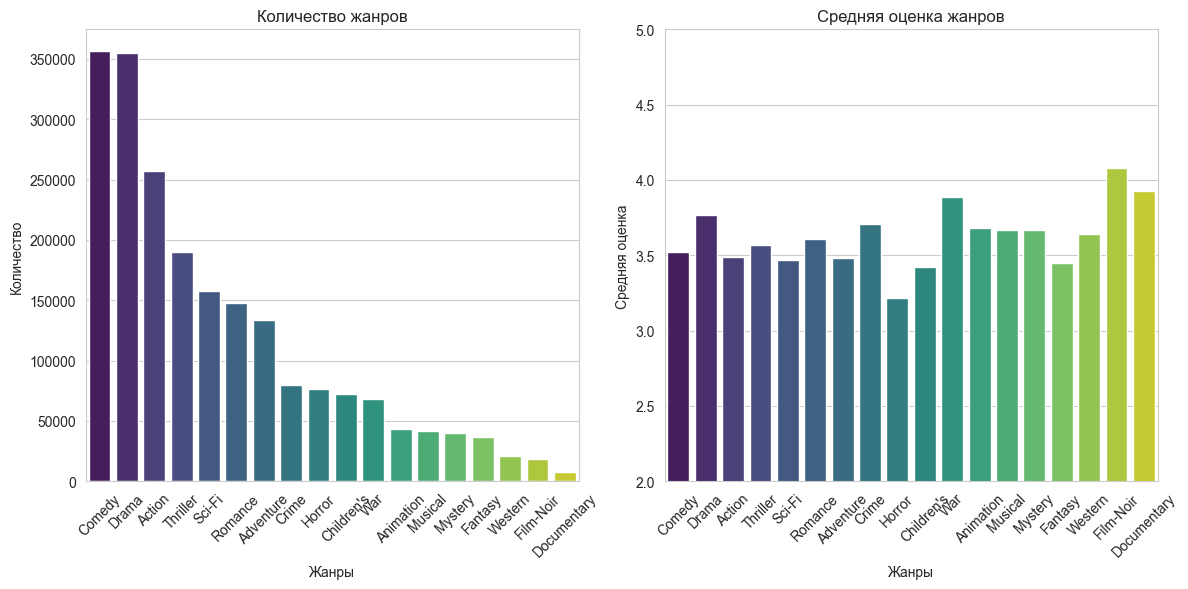

In [20]:
# Анализ Жанров
genres_keys = ("Action","Adventure","Animation","Children's","Comedy","Crime","Documentary","Drama","Fantasy","Film-Noir","Horror","Musical","Mystery","Romance","Sci-Fi","Thriller","War","Western")
genre_stats = (
    movies[['MovieID', 'Genres']]
    .assign(Genre=lambda x: x['Genres'].str.split(r'\s*\|\s*'))
    .explode('Genre')
    .dropna(subset=['Genre'])
    .merge(ratings, on='MovieID', how='inner')
    [['MovieID', 'Genre', 'Rating']]
    .groupby('Genre')['Rating']
    .agg(
        avg_rating='mean',
        count='count'
    )
    .round(2)
    .reset_index()
    .sort_values(by=['count'], ascending=False)
) # type: ignore
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
sns.barplot(x=genre_stats['Genre'], y=genre_stats['count'], hue=genre_stats['Genre'] , palette='viridis', ax=ax1)
ax1.set_title('Количество фильмов по жанрам')
ax1.set_xlabel('Жанры')
ax1.set_ylabel('Количество')
ax1.tick_params(axis='x', rotation=45)

sns.barplot(x=genre_stats['Genre'], y=genre_stats['avg_rating'], hue=genre_stats['Genre'], palette='viridis', ax=ax2)
ax2.set_title('Средняя оценка жанров')
ax2.set_xlabel('Жанры')
ax2.set_ylabel('Средняя оценка')
ax2.set_ylim(2, 5)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

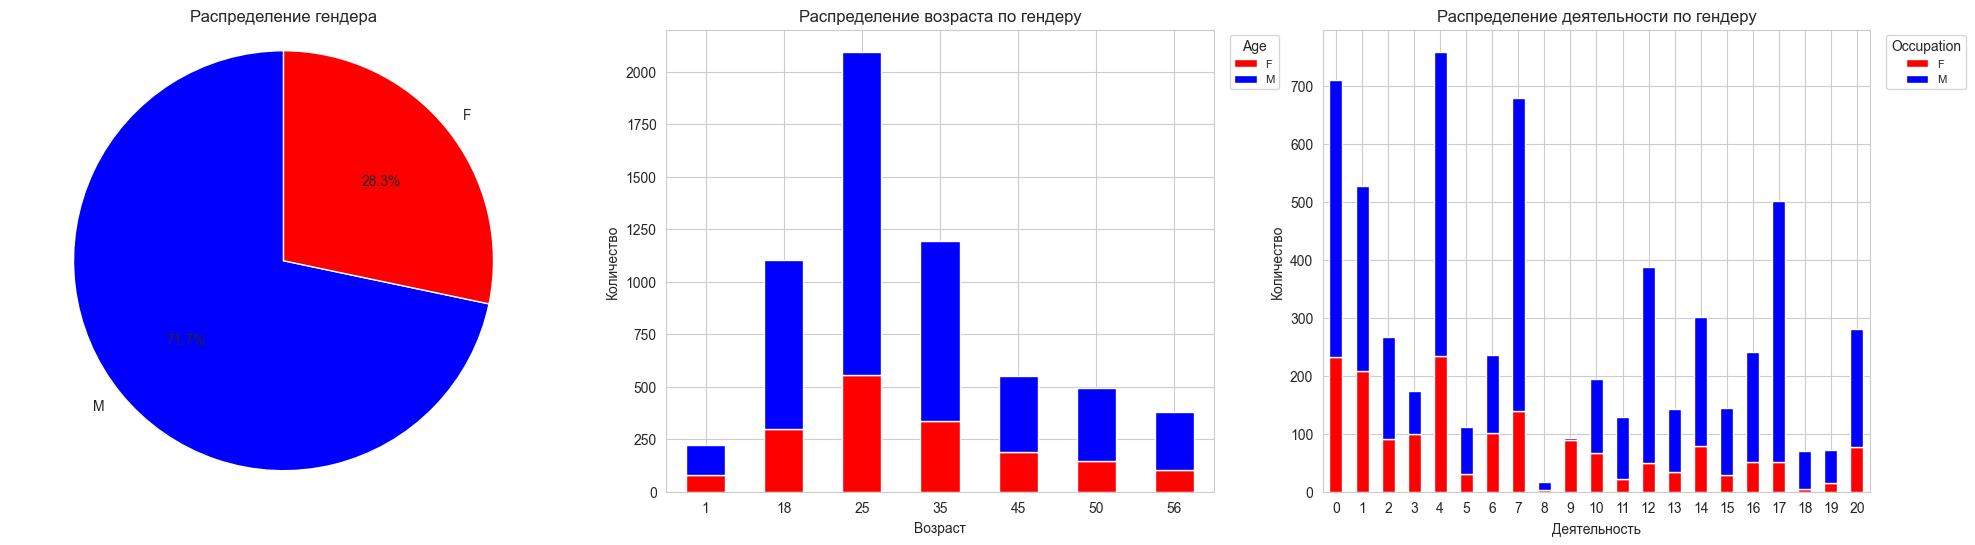

In [22]:
# Анализ Пользователей
users_gender = users['Gender'].value_counts()
users_age = pd.crosstab(users['Age'], users['Gender'])
users_occup = pd.crosstab(users['Occupation'], users['Gender'])

fig ,(ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 6))

ax1.pie(users_gender.values,
        labels=users_gender.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=['blue','red'])
ax1.set_title('Распределение гендера')
ax1.axis('equal')

users_age.plot(kind='bar', stacked=True, ax=ax2, color=['red', 'blue'], edgecolor='white')
ax2.set_title('Распределение возраста по гендеру')
ax2.set_xlabel('Возраст')
ax2.set_ylabel('Количество')
ax2.tick_params(axis='x', rotation=0)
ax2.legend(title='Age', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

users_occup.plot(kind='bar', stacked=True, ax=ax3, color=['red', 'blue'], edgecolor='white')
ax3.set_title('Распределение деятельности по гендеру')
ax3.set_xlabel('Деятельность')
ax3.set_ylabel('Количество')
ax3.tick_params(axis='x', rotation=0)
ax3.legend(title='Occupation', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)

# Анализ Корреляций

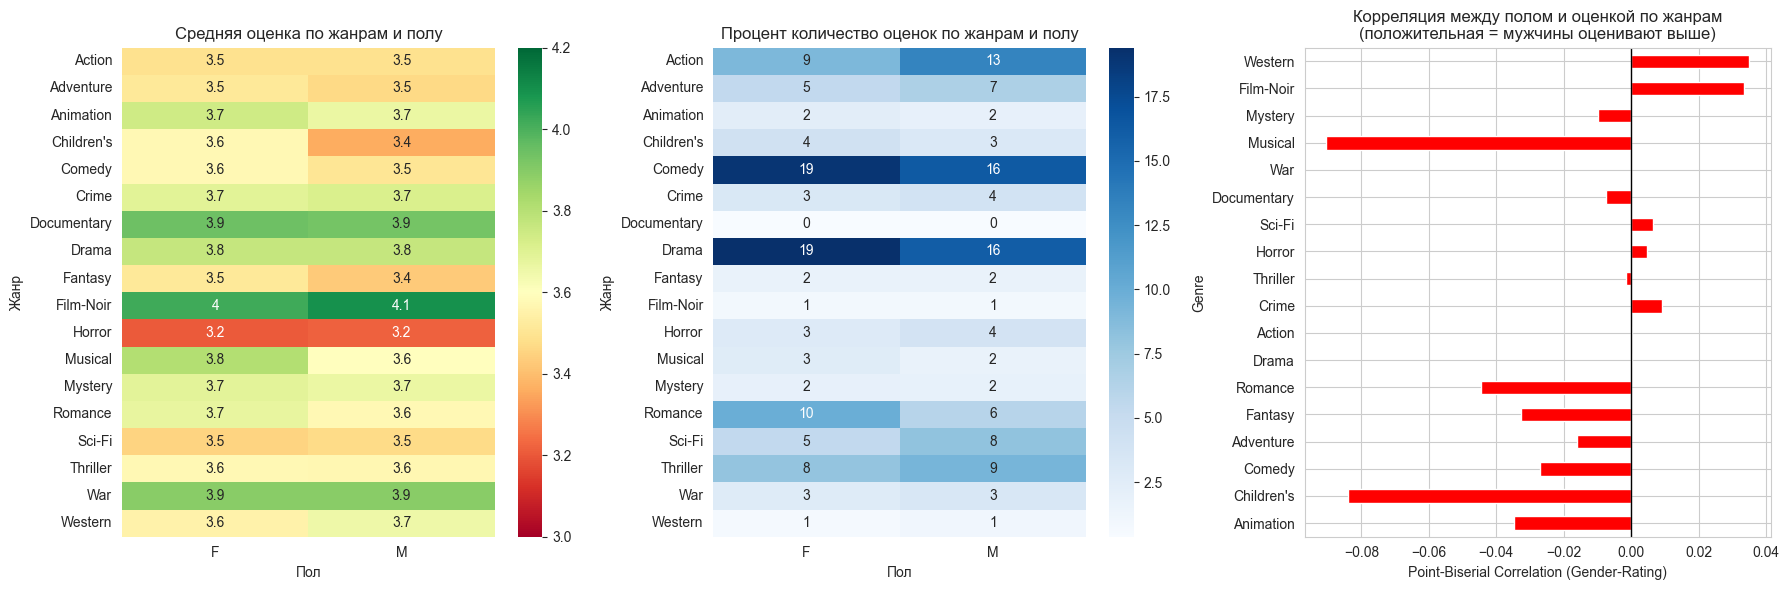

In [77]:
# Полом x Жанр (средняя оценка, количество оценок)
sex_rating_corr = (
    movies[['MovieID', 'Genres']]
    .assign(Genre=lambda x: x['Genres'].str.split(r'\s*\|\s*'))
    .explode('Genre')
    .dropna(subset=['Genre'])
    .merge(ratings, on='MovieID', how='inner')
    [['MovieID', 'UserID', 'Genre', 'Rating']]
    .merge(users, on='UserID', how='inner')
    [['Gender', 'Genre', 'Rating']]
    .groupby(['Gender','Genre'])['Rating']
    .agg(
        avg_rating='mean',
        count='count'
    )
)
common_vmin = min(sex_rating_corr['avg_rating'].min(), 3.0)
common_vmax = max(sex_rating_corr['avg_rating'].max(), 4.2)
rating_pivot = sex_rating_corr.reset_index().pivot(
    index='Genre', 
    columns='Gender', 
    values='avg_rating'
)
count_pivot = sex_rating_corr.reset_index().pivot(
    index='Genre', 
    columns='Gender', 
    values='count'
)
count_pivot = count_pivot.div(count_pivot.sum(axis=0), axis=1) * 100

genre_gender_ratings = (
    movies[['MovieID', 'Genres']]
    .assign(Genre=lambda x: x['Genres'].str.split(r'\s*\|\s*'))
    .explode('Genre')
    .dropna(subset=['Genre'])
    .merge(ratings, on='MovieID', how='inner')
    .merge(users[['UserID', 'Gender']], on='UserID', how='inner')
    .assign(Gender_num=lambda x: (x['Gender'] == 'M').astype(int))
)

correlations = []
for genre in genre_gender_ratings['Genre'].unique():
    genre_data = genre_gender_ratings[genre_gender_ratings['Genre'] == genre]
    if len(genre_data) > 10:
        corr, p_value = pointbiserialr(genre_data['Gender_num'], genre_data['Rating'])
        correlations.append({
            'Genre': genre,
            'Correlation': corr,
            'P_value': p_value,
            'Count': len(genre_data)
        })

corr_df = pd.DataFrame(correlations)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3 , figsize=(18, 6))

sns.heatmap(rating_pivot, cmap='RdYlGn', annot=True, ax=ax1, vmin=common_vmin, vmax=common_vmax)
ax1.set_title('Средняя оценка по жанрам и полу')
ax1.set_xlabel('Пол')
ax1.set_ylabel('Жанр')

sns.heatmap(count_pivot, cmap='Blues', fmt='.0f', annot=True, ax=ax2)
ax2.set_title('Процент количество оценок по жанрам и полу')
ax2.set_xlabel('Пол')
ax2.set_ylabel('Жанр')

corr_plot = corr_df.set_index('Genre')[['Correlation']].plot(
    kind='barh', 
    color=corr_df['Correlation'].apply(lambda x: 'green' if x > 0 else 'red'),
    legend=False,
    ax=ax3
)
ax3.set_xlabel('Point-Biserial Correlation (Gender-Rating)')
ax3.set_title('Корреляция между полом и оценкой по жанрам\n(положительная = мужчины оценивают выше)')
ax3.axvline(x=0, color='black', linewidth=1)

plt.tight_layout()
plt.show()

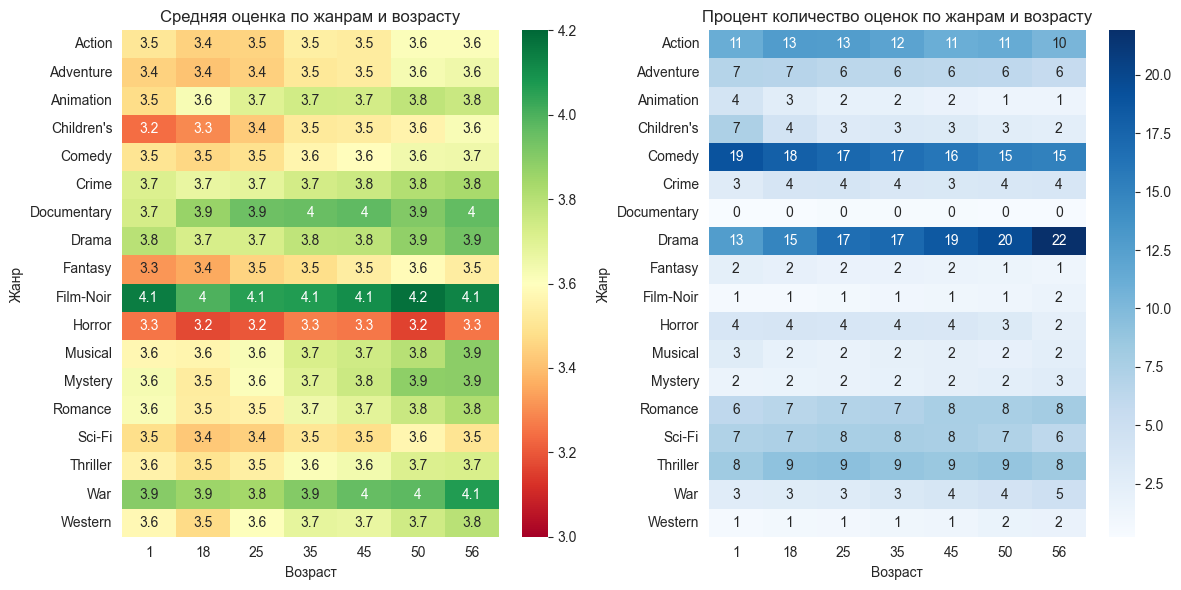

In [ ]:
# Возраст х Жанр (средняя оценка, количество оценок)

age_rating_corr = (
    movies[['MovieID', 'Genres']]
    .assign(Genre=lambda x: x['Genres'].str.split(r'\s*\|\s*'))
    .explode('Genre')
    .dropna(subset=['Genre'])
    .merge(ratings, on='MovieID', how='inner')
    [['MovieID', 'UserID', 'Genre', 'Rating']]
    .merge(users, on='UserID', how='inner')
    [['Age', 'Genre', 'Rating']]
    .groupby(['Age','Genre'])['Rating']
    .agg(
        avg_rating='mean',
        count='count'
    )
)
common_vmin_ar = min(age_rating_corr['avg_rating'].min(), 3.0)
common_vmax_ar = max(age_rating_corr['avg_rating'].max(), 4.2)
rating_pivot_ar = age_rating_corr.reset_index().pivot(
    index='Genre', 
    columns='Age', 
    values='avg_rating'
)
count_pivot_ar = age_rating_corr.reset_index().pivot(
    index='Genre', 
    columns='Age', 
    values='count'
)
count_pivot_ar = count_pivot_ar.div(count_pivot_ar.sum(axis=0), axis=1) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

sns.heatmap(rating_pivot_ar, cmap='RdYlGn', annot=True, ax=ax1, vmin=common_vmin_ar, vmax=common_vmax_ar)
ax1.set_title('Средняя оценка по жанрам и возрасту')
ax1.set_xlabel('Возраст')
ax1.set_ylabel('Жанр')

sns.heatmap(count_pivot_ar, cmap='Blues', fmt='.0f', annot=True, ax=ax2)
ax2.set_title('Процент количество оценок по жанрам и возрасту')
ax2.set_xlabel('Возраст')
ax2.set_ylabel('Жанр')

plt.tight_layout()
plt.show()

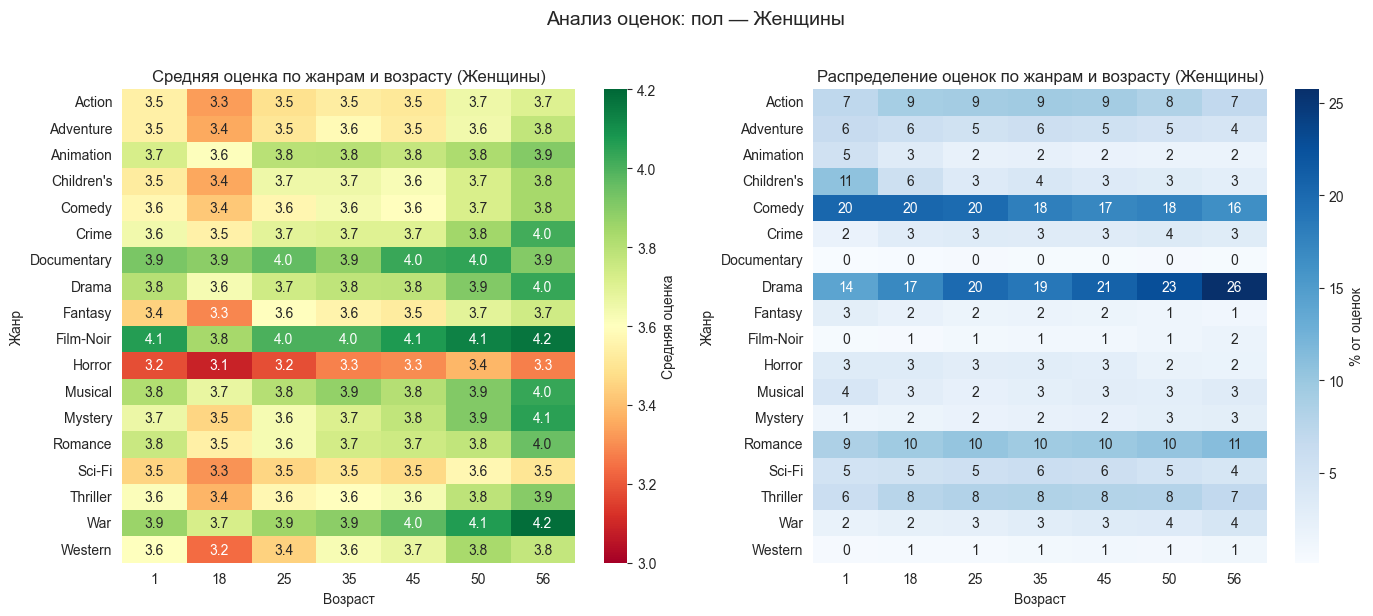

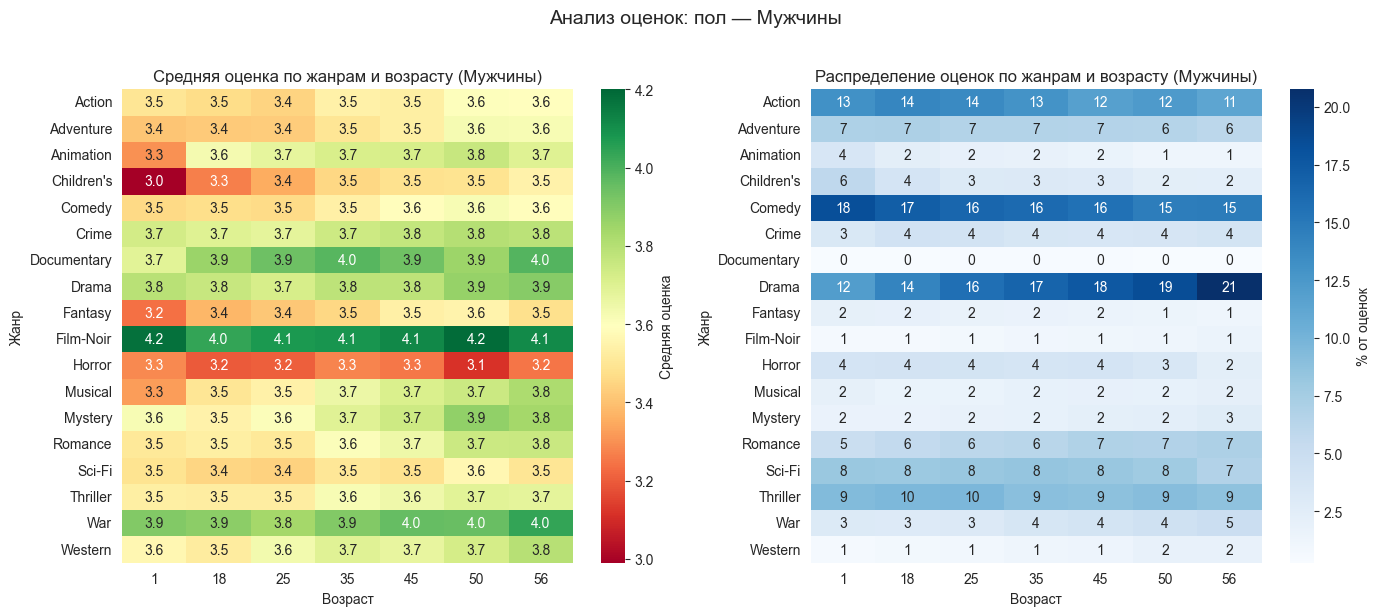

In [ ]:
# Возраст х Жанр | Пол (средняя оценка, количество оценок)
def plot_genre_age_by_gender(gender_label, gender_code, users, movies, ratings):
    """Строит тепловые карты оценок по жанрам и возрасту для указанного пола."""
    
    # Подготовка данных с фильтрацией по полу
    data = (
        movies[['MovieID', 'Genres']]
        .assign(Genre=lambda x: x['Genres'].str.split(r'\s*\|\s*'))
        .explode('Genre')
        .dropna(subset=['Genre'])
        .merge(ratings, on='MovieID', how='inner')
        [['MovieID', 'UserID', 'Genre', 'Rating']]
        .merge(users, on='UserID', how='inner')
        .query("Gender == @gender_code")
        [['Age', 'Genre', 'Rating']]
    )
    
    # Агрегация
    agg_data = (
        data.groupby(['Age','Genre'])['Rating']
        .agg(avg_rating='mean', count='count')
        .reset_index()
    )
    
    # Pivot-таблицы
    rating_pivot = agg_data.pivot(index='Genre', columns='Age', values='avg_rating')
    count_pivot = agg_data.pivot(index='Genre', columns='Age', values='count')
    count_pivot_pct = count_pivot.div(count_pivot.sum(axis=0), axis=1) * 100
    
    # Общие границы для цвета (опционально, для сравнения)
    vmin = min(agg_data['avg_rating'].min(), 3.0)
    vmax = max(agg_data['avg_rating'].max(), 4.2)
    
    # Визуализация
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    sns.heatmap(rating_pivot, cmap='RdYlGn', annot=True, fmt='.1f', 
                ax=ax1, vmin=vmin, vmax=vmax, cbar_kws={'label': 'Средняя оценка'})
    ax1.set_title(f'Средняя оценка по жанрам и возрасту ({gender_label})')
    ax1.set_xlabel('Возраст')
    ax1.set_ylabel('Жанр')
    
    sns.heatmap(count_pivot_pct, cmap='Blues', annot=True, fmt='.0f', 
                ax=ax2, cbar_kws={'label': '% от оценок'})
    ax2.set_title(f'Распределение оценок по жанрам и возрасту ({gender_label})')
    ax2.set_xlabel('Возраст')
    ax2.set_ylabel('Жанр')
    
    plt.suptitle(f'Анализ оценок: пол — {gender_label}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()
    
    return rating_pivot, count_pivot_pct
_, _ = plot_genre_age_by_gender('Женщины', 'F', users, movies, ratings)
_, _ = plot_genre_age_by_gender('Мужчины', 'M', users, movies, ratings)

# Анализ разряженности данных

In [93]:
# Анализ разряженности Пользователь х Оценка
cross_tab = (pd.crosstab(ratings['UserID'], ratings['MovieID']) > 0).astype(int)
filled_pc = np.sum(cross_tab.values) / (cross_tab.shape[0] * cross_tab.shape[1])
print(f'Матрица User X Movie заполнена на {filled_pc*100:.4f}%')


Матрица User X Movie заполнена на 4.4684%


# Анализ по времени

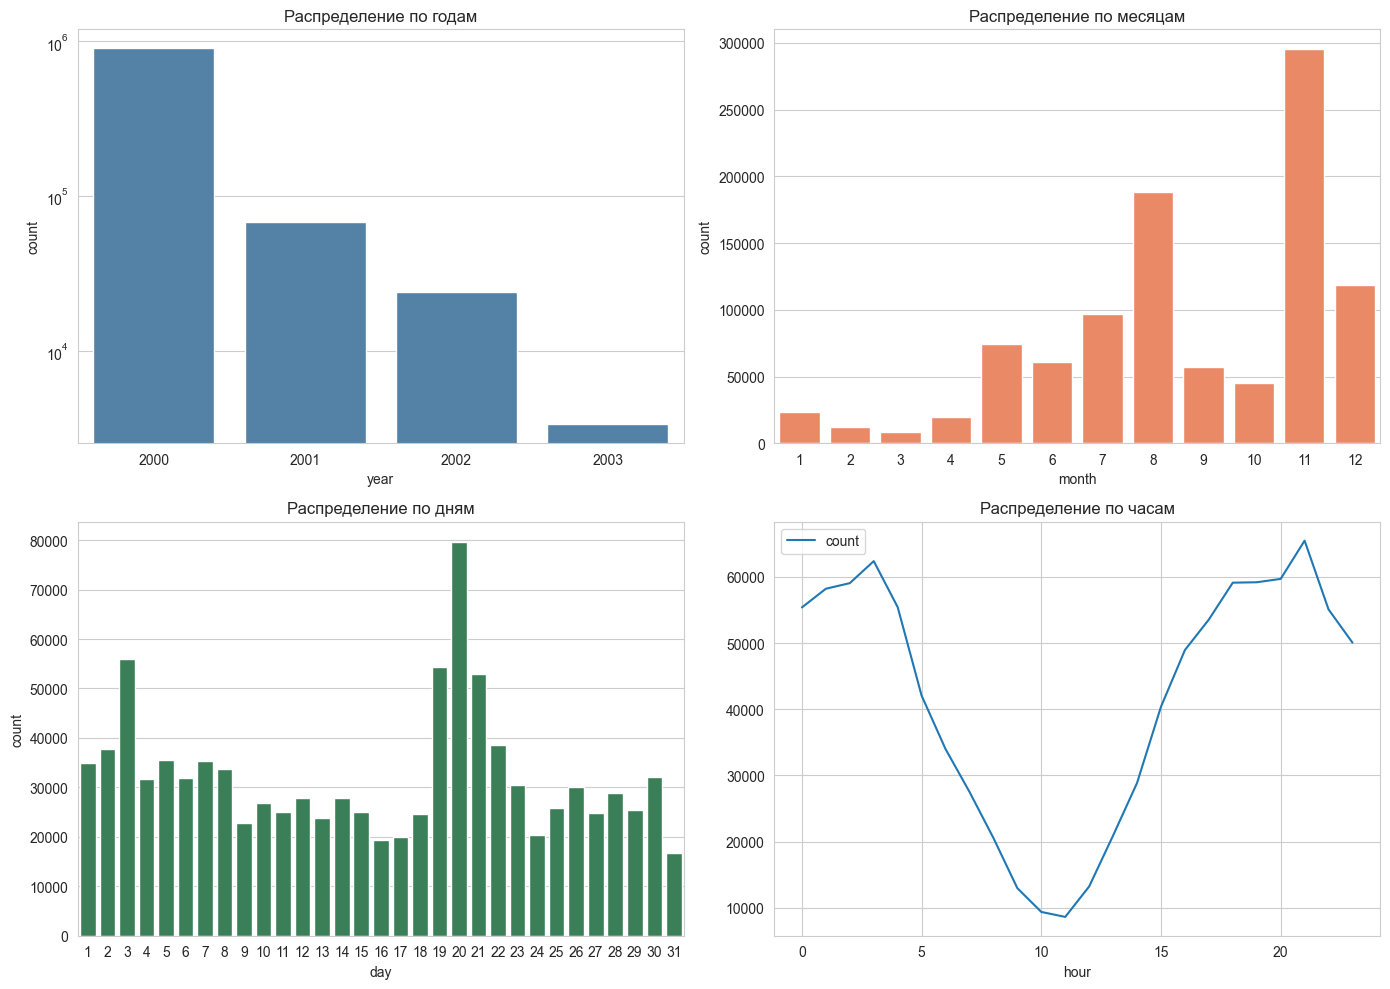

In [ ]:
# Анализ по Год, Месяц, День, Час
timestamp = pd.DataFrame(pd.to_datetime(ratings['Timestamp'], unit='s'))
timestamp['year'] = timestamp['Timestamp'].dt.year
timestamp['month'] = timestamp['Timestamp'].dt.month
timestamp['day'] = timestamp['Timestamp'].dt.day
timestamp['hour'] = timestamp['Timestamp'].dt.hour 

hour_stat = pd.DataFrame(timestamp['hour'].value_counts().sort_index())

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=timestamp, x='year', ax=ax[0, 0], color='steelblue')
ax[0, 0].set_yscale('log')
ax[0, 0].set_title('Распределение по годам')

sns.countplot(data=timestamp, x='month', ax=ax[0, 1], color='coral')
ax[0, 1].set_title('Распределение по месяцам')

sns.countplot(data=timestamp, x='day', ax=ax[1, 0], color='seagreen')
ax[1, 0].set_title('Распределение по дням')

sns.lineplot(data=hour_stat, ax=ax[1, 1], color='mediumpurple')
ax[1, 1].set_title('Распределение по часам')

plt.tight_layout()
plt.show()

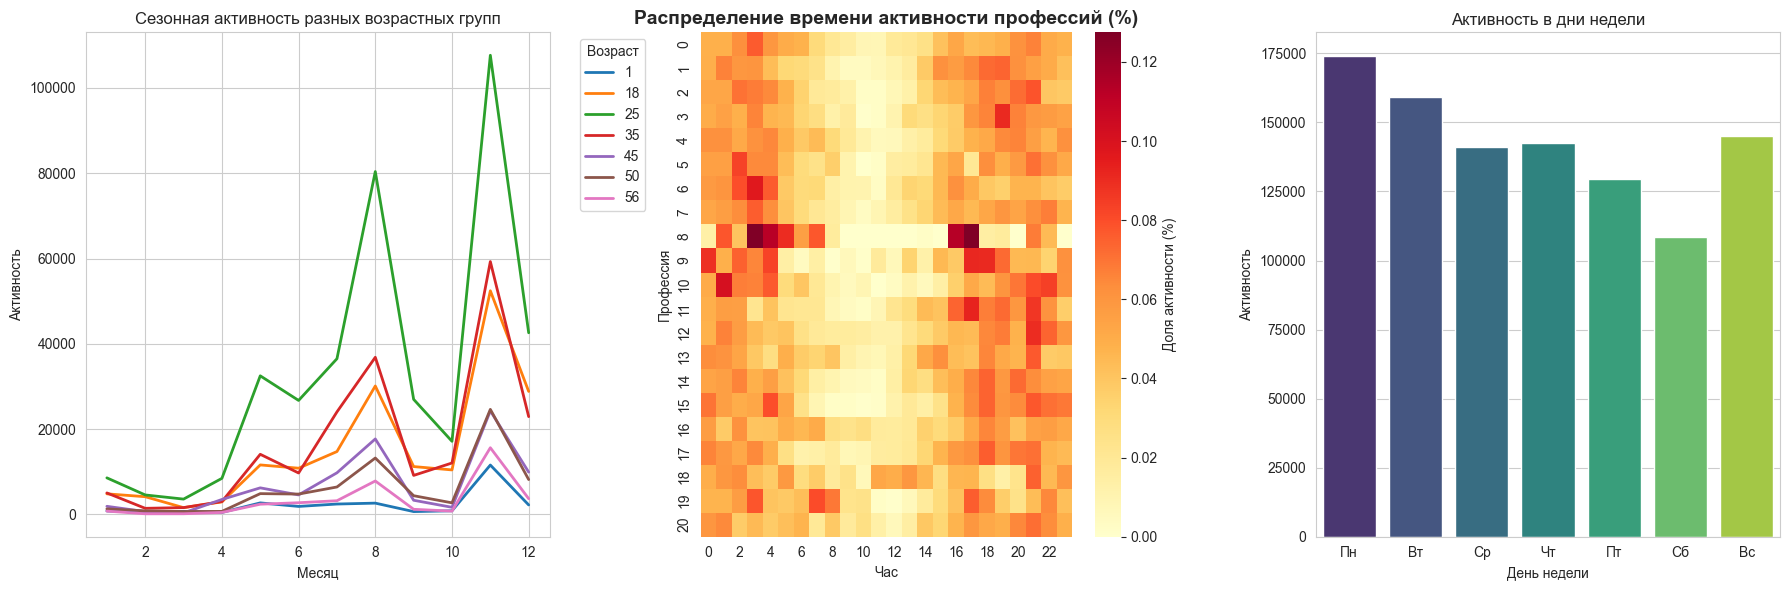

In [165]:
# Анализ связей веремени и другой информации
user_time = (
    users
    .merge(ratings, on='UserID', how='inner')
    [['Age', 'Occupation', 'Timestamp']]
)
user_time['Timestamp'] = pd.to_datetime(user_time['Timestamp'], unit='s')
user_time['month'] = user_time['Timestamp'].dt.month
user_time['dayofweek'] = user_time['Timestamp'].dt.dayofweek
user_time['hour'] = user_time['Timestamp'].dt.hour

month_age_data = user_time.groupby(['month', 'Age']).size().reset_index(name='count')
dayofweek_data = user_time.groupby('dayofweek').size().reset_index(name='count')

pivot_pct= pd.crosstab(user_time['Occupation'], user_time['hour'], normalize='index')

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.lineplot(data=month_age_data, x='month', y='count', hue='Age', palette='tab10',
             estimator='sum', errorbar=None, linewidth=2, ax=axes[0])
axes[0].set_title('Сезонная активность разных возрастных групп')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Активность')
axes[0].legend(title='Возраст', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=1)

sns.heatmap(pivot_pct, cmap='YlOrRd', annot=False, fmt='.1%', 
            cbar_kws={'label': 'Доля активности (%)'}, ax=axes[1])
axes[1].set_title('Распределение времени активности профессий (%)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Час')
axes[1].set_ylabel('Профессия')

day_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
dayofweek_data['day_name'] = dayofweek_data['dayofweek'].map(dict(enumerate(day_names)))

sns.barplot(data=dayofweek_data, x='day_name', y='count', ax=axes[2], hue='day_name', palette='viridis')
axes[2].set_title('Активность в дни недели')
axes[2].set_xlabel('День недели')
axes[2].set_ylabel('Активность')

plt.tight_layout()
plt.show()
